In [1]:
#palie1
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# --- Étape A : Le chemin exact d'après vos photos ---
# Note : Kaggle transforme souvent "Alzheimer_DataSet" en "alzheimer-dataset"
DATASET_PATH = '/kaggle/input/datasets/souriabdelmouhib/alzheimer-dataset/DataScoop'

# --- Étape B : Configuration du "Generator" ---
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=10,
    horizontal_flip=True,
    fill_mode='nearest'
)

# --- Étape C : Création des flux ---
try:
    train_generator = datagen.flow_from_directory(
        DATASET_PATH,
        target_size=(224, 224),
        batch_size=64,
        class_mode='categorical',
        subset='training',
        shuffle=True
    )

    val_generator = datagen.flow_from_directory(
        DATASET_PATH,
        target_size=(224, 224),
        batch_size=64,
        class_mode='categorical',
        subset='validation',
        shuffle=False
    )
    print(f"Succès ! Classes détectées : {train_generator.class_indices}")
except Exception as e:
    print(f"Erreur : {e}")
    print("Vérifiez le nom du dossier en cliquant sur l'icône 'Copier le chemin' dans le volet Input à droite.")

2026-03-23 19:03:27.842853: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1774292608.043229      25 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1774292608.098311      25 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1774292608.608383      25 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774292608.608421      25 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774292608.608425      25 computation_placer.cc:177] computation placer alr

Found 40321 images belonging to 4 classes.
Found 10079 images belonging to 4 classes.
Succès ! Classes détectées : {'MildDemented': 0, 'ModerateDemented': 1, 'NonDemented': 2, 'VeryMildDemented': 3}


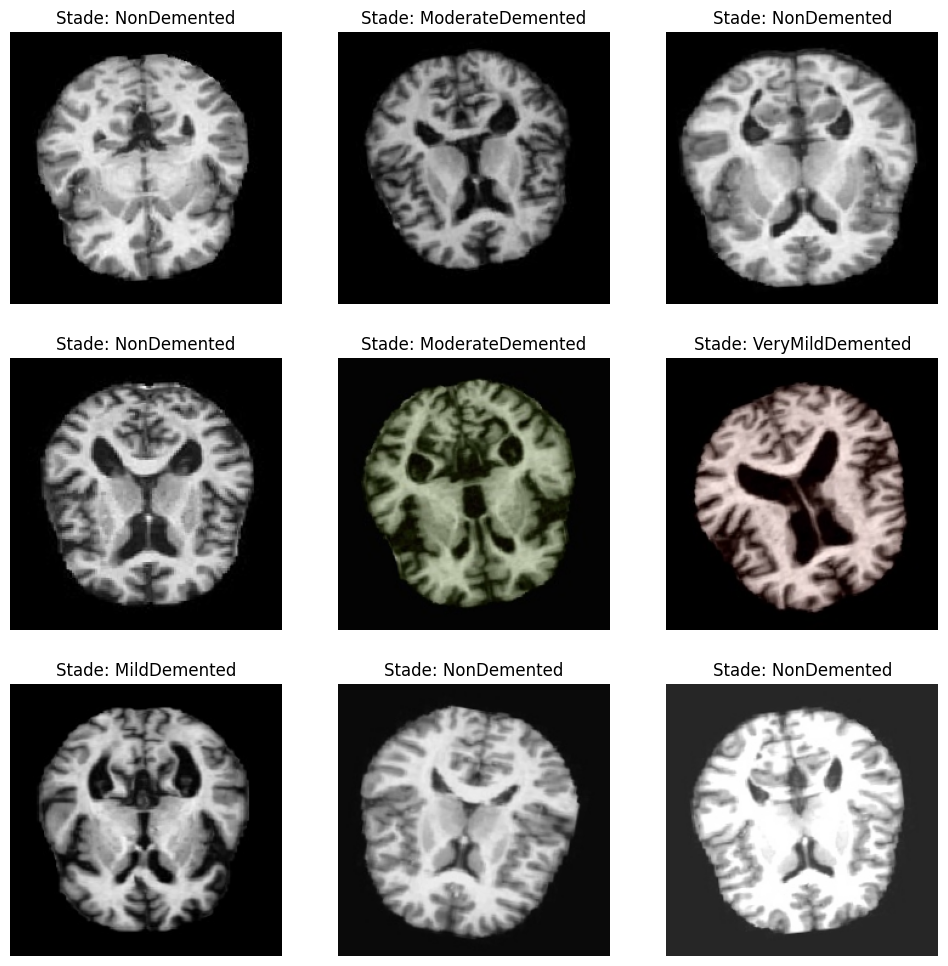

In [2]:
# On vérifie visuellement que les images sortent bien du dossier DataScoop
images, labels = next(train_generator)
class_labels = list(train_generator.class_indices.keys())

plt.figure(figsize=(12, 12))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i])
    label_idx = np.argmax(labels[i])
    plt.title(f"Stade: {class_labels[label_idx]}")
    plt.axis('off')
plt.show()

In [3]:
#palie2
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# --- Étape A : Charger la base ResNet50 ---
# include_top=False : On enlève la dernière couche originale (qui est faite pour 1000 objets)
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# --- Étape B : Geler les connaissances ---
# On dit au modèle : "Ne change pas tes neurones de base pour l'instant"
base_model.trainable = False 

# --- Étape C : Ajouter notre spécialisation Alzheimer ---
x = base_model.output
x = GlobalAveragePooling2D()(x) # Réduit la complexité spatiale
x = BatchNormalization()(x)     # Stabilise et accélère l'apprentissage
x = Dense(512, activation='relu')(x) # Couche de décision intermédiaire
x = Dropout(0.5)(x)             # Éteint 50% des neurones au hasard pour éviter l'apprentissage par cœur (Overfitting)
x = Dense(256, activation='relu')(x)

# --- Étape D : La sortie finale (Les 4 Stades) ---
# Softmax donne un score sur 100 pour chaque classe
predictions = Dense(4, activation='softmax')(x)

# --- Étape E : Assemblage et Compilation ---
model = Model(inputs=base_model.input, outputs=predictions)

model.compile(
    optimizer=Adam(learning_rate=0.001), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)

# Résumé du cerveau créé
model.summary()

I0000 00:00:1774292668.241446      25 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1774292668.247421      25 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,777,348 (94.52 MB)

 Trainable params: 1,185,540 (4.52 MB)

 Non-trainable params: 23,591,808 (90.00 MB)

In [4]:
#palie3
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# --- Étape A : Définition des gardes-fous (Callbacks) ---
callbacks = [
    # 1. EarlyStopping : Arrête si le modèle n'apprend plus rien après 5 époques. 
    # Cela évite de gaspiller du temps et de l'énergie.
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    
    # 2. ReduceLROnPlateau : Si le modèle stagne, on réduit la vitesse d'apprentissage (Learning Rate).
    # C'est comme demander au modèle d'être plus précis dans ses derniers ajustements.
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=0.00001, verbose=1),
    
    # 3. ModelCheckpoint : Sauvegarde AUTOMATIQUEMENT la meilleure version du modèle.
    # Ce fichier sera votre produit final (.h5).
    ModelCheckpoint('alzheimer_resnet50_model.h5', monitor='val_accuracy', save_best_only=True, verbose=1)
]

# --- Étape B : Lancement de l'apprentissage ---
# On utilise fit() pour marier le modèle (Pilier 2) avec les données (Pilier 1)
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20, # On prévoit 20 passages, mais l'EarlyStopping peut arrêter avant
    callbacks=callbacks,
    verbose=1
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20


I0000 00:00:1774292681.357031      85 service.cc:152] XLA service 0x7bec100035e0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1774292681.357081      85 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1774292681.357088      85 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1774292683.542729      85 cuda_dnn.cc:529] Loaded cuDNN version 91002


  1/631 ━━━━━━━━━━━━━━━━━━━━ 3:08:07 18s/step - accuracy: 0.2500 - loss: 1.4164

I0000 00:00:1774292691.264407      85 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


631/631 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5036 - loss: 1.1037
Epoch 1: val_accuracy improved from -inf to 0.63717, saving model to alzheimer_resnet50_model.h5


... (15 outputs left out)

631/631 ━━━━━━━━━━━━━━━━━━━━ 616s 976ms/step - accuracy: 0.8291 - loss: 0.4089 - val_accuracy: 0.8567 - val_loss: 0.3553 - learning_rate: 0.0010
Epoch 17/20
631/631 ━━━━━━━━━━━━━━━━━━━━ 0s 779ms/step - accuracy: 0.8370 - loss: 0.3930
Epoch 17: val_accuracy improved from 0.85673 to 0.86229, saving model to alzheimer_resnet50_model.h5


631/631 ━━━━━━━━━━━━━━━━━━━━ 618s 980ms/step - accuracy: 0.8370 - loss: 0.3930 - val_accuracy: 0.8623 - val_loss: 0.3439 - learning_rate: 0.0010
Epoch 18/20
631/631 ━━━━━━━━━━━━━━━━━━━━ 0s 787ms/step - accuracy: 0.8436 - loss: 0.3784
Epoch 18: val_accuracy improved from 0.86229 to 0.86953, saving model to alzheimer_resnet50_model.h5


631/631 ━━━━━━━━━━━━━━━━━━━━ 626s 992ms/step - accuracy: 0.8436 - loss: 0.3784 - val_accuracy: 0.8695 - val_loss: 0.3343 - learning_rate: 0.0010
Epoch 19/20
631/631 ━━━━━━━━━━━━━━━━━━━━ 0s 784ms/step - accuracy: 0.8533 - loss: 0.3587
Epoch 19: val_accuracy did not improve from 0.86953
631/631 ━━━━━━━━━━━━━━━━━━━━ 620s 982ms/step - accuracy: 0.8533 - loss: 0.3587 - val_accuracy: 0.8685 - val_loss: 0.3355 - learning_rate: 0.0010
Epoch 20/20
631/631 ━━━━━━━━━━━━━━━━━━━━ 0s 790ms/step - accuracy: 0.8535 - loss: 0.3572
Epoch 20: val_accuracy improved from 0.86953 to 0.86993, saving model to alzheimer_resnet50_model.h5


631/631 ━━━━━━━━━━━━━━━━━━━━ 627s 993ms/step - accuracy: 0.8535 - loss: 0.3572 - val_accuracy: 0.8699 - val_loss: 0.3290 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 20.


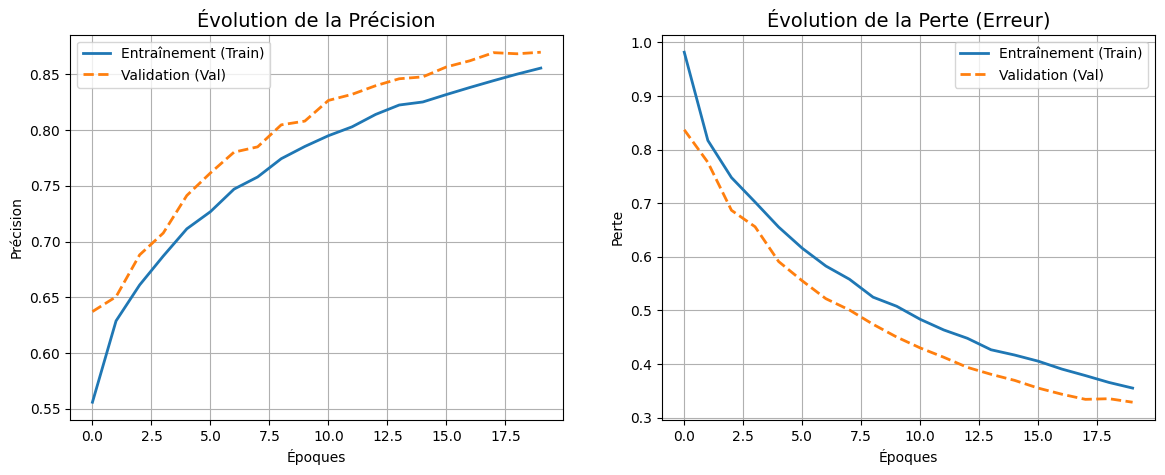

In [5]:
#palie4
import matplotlib.pyplot as plt

# Création d'une figure avec deux graphiques (1 ligne, 2 colonnes)
plt.figure(figsize=(14, 5))

# Graphique 1 : La Précision (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Entraînement (Train)', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Validation (Val)', linewidth=2, linestyle='--')
plt.title('Évolution de la Précision', fontsize=14)
plt.xlabel('Époques')
plt.ylabel('Précision')
plt.legend()
plt.grid(True)

# Graphique 2 : L'Erreur (Loss)
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Entraînement (Train)', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation (Val)', linewidth=2, linestyle='--')
plt.title('Évolution de la Perte (Erreur)', fontsize=14)
plt.xlabel('Époques')
plt.ylabel('Perte')
plt.legend()
plt.grid(True)

# Affichage
plt.show()

158/158 ━━━━━━━━━━━━━━━━━━━━ 122s 749ms/step


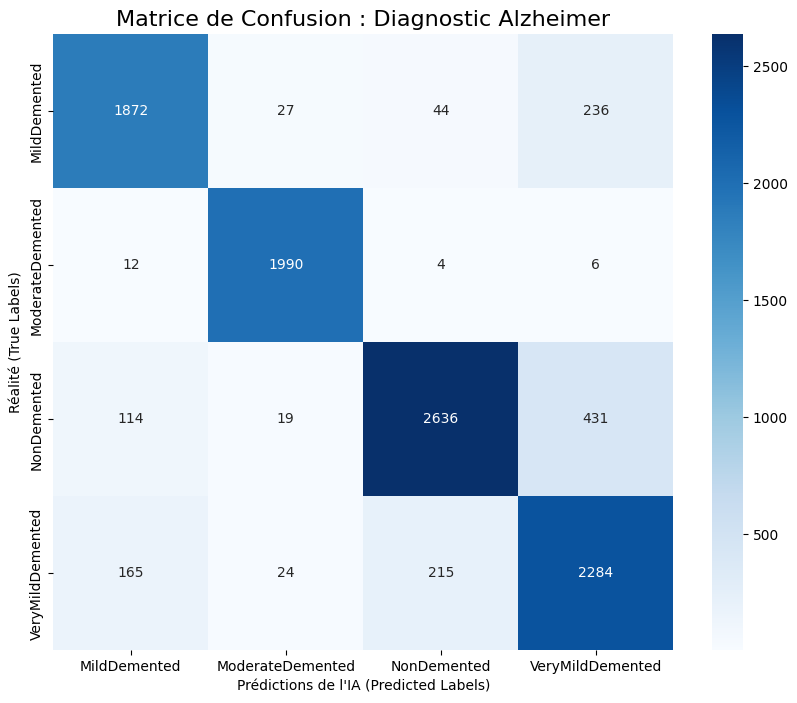


--- Rapport de Classification détaillé ---
                  precision    recall  f1-score   support

    MildDemented       0.87      0.86      0.86      2179
ModerateDemented       0.97      0.99      0.98      2012
     NonDemented       0.91      0.82      0.86      3200
VeryMildDemented       0.77      0.85      0.81      2688

        accuracy                           0.87     10079
       macro avg       0.88      0.88      0.88     10079
    weighted avg       0.87      0.87      0.87     10079



In [6]:
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# 1. Obtenir les vraies étiquettes et les prédictions
# On réinitialise le générateur pour être sûr de l'ordre des images
val_generator.reset()
Y_pred = model.predict(val_generator)
y_pred = np.argmax(Y_pred, axis=1)
y_true = val_generator.classes

# 2. Créer la matrice de confusion
cm = confusion_matrix(y_true, y_pred)

# 3. Affichage graphique avec Seaborn
plt.figure(figsize=(10, 8))
labels = list(val_generator.class_indices.keys())
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=labels, yticklabels=labels)

plt.title('Matrice de Confusion : Diagnostic Alzheimer', fontsize=16)
plt.ylabel('Réalité (True Labels)')
plt.xlabel('Prédictions de l\'IA (Predicted Labels)')
plt.show()

# 4. Afficher le rapport détaillé (Précision, Rappel, F1-Score)
print("\n--- Rapport de Classification détaillé ---")
print(classification_report(y_true, y_pred, target_names=labels))

In [7]:
import os
print(os.listdir('/kaggle/working'))

['alzheimer_resnet50_model.h5', '__notebook__.ipynb']


In [8]:
#passer de 87% à plus de 90%

In [9]:
from tensorflow.keras.models import load_model

# 1. Charger ton modèle à 87%
# Note : Si tu as fait un "Save Version" hier, le fichier est dans /kaggle/working/
model = load_model('/kaggle/input/notebooks/souriabdelmouhib/notebook5252fb6542/alzheimer_resnet50_model.h5')

print("✅ Modèle V1 chargé avec succès !")
print("Prêt à passer de 87% à plus de 90%.")

# 2. Petite vérification pour être sûr
loss, acc = model.evaluate(val_generator)
print(f"Validation actuelle : {acc*100:.2f}%")

✅ Modèle V1 chargé avec succès !
Prêt à passer de 87% à plus de 90%.
158/158 ━━━━━━━━━━━━━━━━━━━━ 121s 731ms/step - accuracy: 0.8953 - loss: 0.2669
Validation actuelle : 86.80%


In [10]:
# --- PHASE 2 : FINE-TUNING CHIRURGICAL ---

# 1. On autorise l'entraînement sur le modèle chargé
model.trainable = True

# 2. On gèle les 100 premières couches (les bases restent fixes)
# On ne ré-entraîne que les couches "médicales" du haut
for layer in model.layers[:100]:
    layer.trainable = False

# 3. Compilation avec un Learning Rate TRÈS faible (1e-5)
# Si on met un chiffre trop gros, on risque de perdre les 87% acquis.
from tensorflow.keras.optimizers import Adam
model.compile(optimizer=Adam(learning_rate=1e-5), 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

# 4. On lance l'entraînement (10 époques pour commencer)
# On utilise tes générateurs de données déjà prêts
history_fine = model.fit(
    train_generator,
    epochs=10,
    validation_data=val_generator
)

Epoch 1/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 645s 1s/step - accuracy: 0.8570 - loss: 0.3524 - val_accuracy: 0.8776 - val_loss: 0.3147
Epoch 2/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 608s 964ms/step - accuracy: 0.8675 - loss: 0.3272 - val_accuracy: 0.8830 - val_loss: 0.3076
Epoch 3/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 611s 969ms/step - accuracy: 0.8697 - loss: 0.3218 - val_accuracy: 0.8818 - val_loss: 0.3035
Epoch 4/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 622s 985ms/step - accuracy: 0.8695 - loss: 0.3195 - val_accuracy: 0.8842 - val_loss: 0.2984
Epoch 5/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 615s 974ms/step - accuracy: 0.8716 - loss: 0.3245 - val_accuracy: 0.8893 - val_loss: 0.2915
Epoch 6/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 613s 972ms/step - accuracy: 0.8718 - loss: 0.3134 - val_accuracy: 0.8885 - val_loss: 0.2898
Epoch 7/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 606s 961ms/step - accuracy: 0.8750 - loss: 0.3103 - val_accuracy: 0.8916 - val_loss: 0.2857
Epoch 8/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 608s 964ms/step - accuracy: 0.8803 - lo

In [11]:
# --- PHASE 3 : FINE-TUNING AVEC SÉCURITÉ (CALLBACKS) ---

# 1. On autorise l'entraînement (Fine-Tuning)
model.trainable = True

# 2. On gèle les 100 premières couches (Bases solides)
for layer in model.layers[:100]:
    layer.trainable = False

# 3. Compilation (Pas de fourmi : 1e-5)
from tensorflow.keras.optimizers import Adam
model.compile(optimizer=Adam(learning_rate=1e-5), 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

# 4. Configuration des Callbacks (Tes gardes du corps)
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

checkpoint = ModelCheckpoint(
    'best_alzheimer_model.h5', 
    monitor='val_accuracy', 
    save_best_only=True, 
    mode='max',
    verbose=1
)

early_stop = EarlyStopping(
    monitor='val_loss', 
    patience=3, 
    restore_best_weights=True, # <--- Remet l'époque 6 (ou la meilleure) à la fin
    verbose=1
)

# 5. Lancement de l'entraînement final
history_fine = model.fit(
    train_generator,
    epochs=20, # On met 20 car EarlyStopping s'arrêtera tout seul dès que ça sature
    validation_data=val_generator,
    callbacks=[checkpoint, early_stop]
)

Epoch 1/20
631/631 ━━━━━━━━━━━━━━━━━━━━ 0s 766ms/step - accuracy: 0.8802 - loss: 0.3004
Epoch 1: val_accuracy improved from -inf to 0.89195, saving model to best_alzheimer_model.h5


631/631 ━━━━━━━━━━━━━━━━━━━━ 620s 966ms/step - accuracy: 0.8802 - loss: 0.3004 - val_accuracy: 0.8920 - val_loss: 0.2793
Epoch 2/20
631/631 ━━━━━━━━━━━━━━━━━━━━ 0s 771ms/step - accuracy: 0.8819 - loss: 0.2908
Epoch 2: val_accuracy improved from 0.89195 to 0.89592, saving model to best_alzheimer_model.h5


631/631 ━━━━━━━━━━━━━━━━━━━━ 608s 964ms/step - accuracy: 0.8819 - loss: 0.2908 - val_accuracy: 0.8959 - val_loss: 0.2730
Epoch 3/20
631/631 ━━━━━━━━━━━━━━━━━━━━ 0s 774ms/step - accuracy: 0.8809 - loss: 0.2940
Epoch 3: val_accuracy improved from 0.89592 to 0.89731, saving model to best_alzheimer_model.h5


631/631 ━━━━━━━━━━━━━━━━━━━━ 620s 983ms/step - accuracy: 0.8809 - loss: 0.2940 - val_accuracy: 0.8973 - val_loss: 0.2734
Epoch 4/20
631/631 ━━━━━━━━━━━━━━━━━━━━ 0s 762ms/step - accuracy: 0.8857 - loss: 0.2911
Epoch 4: val_accuracy improved from 0.89731 to 0.89900, saving model to best_alzheimer_model.h5


631/631 ━━━━━━━━━━━━━━━━━━━━ 604s 957ms/step - accuracy: 0.8857 - loss: 0.2911 - val_accuracy: 0.8990 - val_loss: 0.2689
Epoch 5/20
631/631 ━━━━━━━━━━━━━━━━━━━━ 0s 757ms/step - accuracy: 0.8832 - loss: 0.2888
Epoch 5: val_accuracy improved from 0.89900 to 0.89969, saving model to best_alzheimer_model.h5


631/631 ━━━━━━━━━━━━━━━━━━━━ 599s 950ms/step - accuracy: 0.8832 - loss: 0.2888 - val_accuracy: 0.8997 - val_loss: 0.2689
Epoch 6/20
631/631 ━━━━━━━━━━━━━━━━━━━━ 0s 821ms/step - accuracy: 0.8835 - loss: 0.2889
Epoch 6: val_accuracy did not improve from 0.89969
631/631 ━━━━━━━━━━━━━━━━━━━━ 650s 1s/step - accuracy: 0.8835 - loss: 0.2889 - val_accuracy: 0.8978 - val_loss: 0.2731
Epoch 7/20
631/631 ━━━━━━━━━━━━━━━━━━━━ 0s 783ms/step - accuracy: 0.8869 - loss: 0.2864
Epoch 7: val_accuracy did not improve from 0.89969
631/631 ━━━━━━━━━━━━━━━━━━━━ 619s 981ms/step - accuracy: 0.8869 - loss: 0.2864 - val_accuracy: 0.8935 - val_loss: 0.2706
Epoch 8/20
631/631 ━━━━━━━━━━━━━━━━━━━━ 0s 761ms/step - accuracy: 0.8869 - loss: 0.2844
Epoch 8: val_accuracy did not improve from 0.89969
631/631 ━━━━━━━━━━━━━━━━━━━━ 600s 951ms/step - accuracy: 0.8869 - loss: 0.2844 - val_accuracy: 0.8988 - val_loss: 0.2707
Epoch 8: early stopping
Restoring model weights from the end of the best epoch: 5.


⏱️ Chargement du modèle champion...


✅ Modèle à ~89% chargé !
⏱️ Calcul des prédictions sur les données de validation...
158/158 ━━━━━━━━━━━━━━━━━━━━ 118s 720ms/step
⏱️ Création de la matrice de confusion...


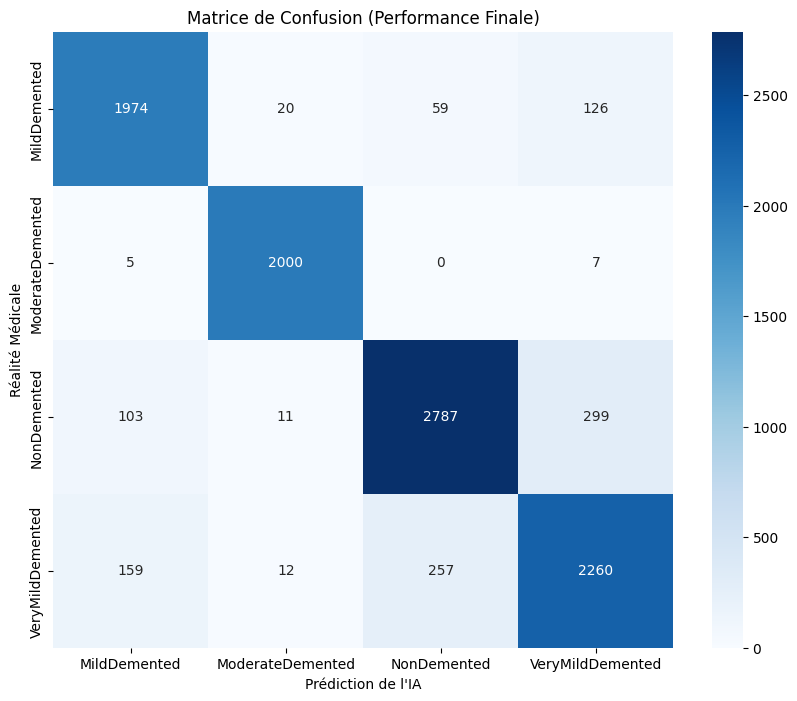


📝 Rapport de classification détaillé :
                  precision    recall  f1-score   support

    MildDemented       0.88      0.91      0.89      2179
ModerateDemented       0.98      0.99      0.99      2012
     NonDemented       0.90      0.87      0.88      3200
VeryMildDemented       0.84      0.84      0.84      2688

        accuracy                           0.90     10079
       macro avg       0.90      0.90      0.90     10079
    weighted avg       0.89      0.90      0.89     10079



In [12]:
from tensorflow.keras.models import load_model
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# A. Charger le modèle champion
print("⏱️ Chargement du modèle champion...")
model = load_model('/kaggle/input/notebooks/souriabdelmouhib/notebook5252fb6542/best_alzheimer_model.h5')
print("✅ Modèle à ~89% chargé !")

# B. Générer les prédictions (assure-toi que val_generator existe déjà)
print("⏱️ Calcul des prédictions sur les données de validation...")
val_generator.reset() # Important !
Y_pred = model.predict(val_generator)
y_pred = np.argmax(Y_pred, axis=1)
y_true = val_generator.classes
class_labels = list(val_generator.class_indices.keys())

# C. Créer la Matrice de Confusion graphique
print("⏱️ Création de la matrice de confusion...")
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', # 'd' pour afficher les nombres réels
            xticklabels=class_labels, yticklabels=class_labels)
plt.title('Matrice de Confusion (Performance Finale)')
plt.ylabel('Réalité Médicale')
plt.xlabel('Prédiction de l\'IA')
plt.show()

# D. Afficher les statistiques de précision détaillées
print("\n📝 Rapport de classification détaillé :")
print(classification_report(y_true, y_pred, target_names=class_labels))

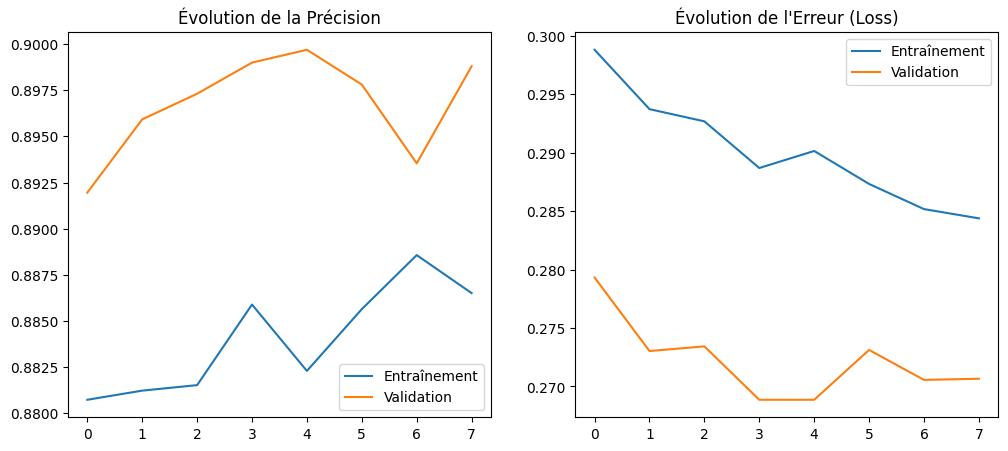

In [13]:
# Uniquement si tu n'as pas redémarré la session !
plt.figure(figsize=(12, 5))

# Courbe de l'Accuracy (Précision)
plt.subplot(1, 2, 1)
plt.plot(history_fine.history['accuracy'], label='Entraînement')
plt.plot(history_fine.history['val_accuracy'], label='Validation')
plt.title('Évolution de la Précision')
plt.legend()

# Courbe de la Perte (Loss/Erreur)
plt.subplot(1, 2, 2)
plt.plot(history_fine.history['loss'], label='Entraînement')
plt.plot(history_fine.history['val_loss'], label='Validation')
plt.title('Évolution de l\'Erreur (Loss)')
plt.legend()

plt.show()

In [14]:
#92%-93%
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# 1. On débloque plus de couches pour plus de flexibilité
model.trainable = True
for layer in model.layers[:50]: # On ne garde que les 50 premières couches gelées
    layer.trainable = False

# 2. On compile avec un taux d'apprentissage "chirurgical"
model.compile(
    optimizer=Adam(learning_rate=5e-6), # Encore plus petit pour la précision
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 3. Les 3 Gardes du corps
checkpoint = ModelCheckpoint('ultra_best_model.h5', monitor='val_accuracy', save_best_only=True, mode='max', verbose=1)

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)

# NOUVEAU : Réduit la vitesse si on stagne
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=1e-7, verbose=1)

# 4. Entraînement final
history_ultimate = model.fit(
    train_generator,
    epochs=25, 
    validation_data=val_generator,
    callbacks=[checkpoint, early_stop, reduce_lr]
)

Epoch 1/25
631/631 ━━━━━━━━━━━━━━━━━━━━ 0s 792ms/step - accuracy: 0.8860 - loss: 0.2807
Epoch 1: val_accuracy improved from -inf to 0.89414, saving model to ultra_best_model.h5


631/631 ━━━━━━━━━━━━━━━━━━━━ 639s 996ms/step - accuracy: 0.8860 - loss: 0.2808 - val_accuracy: 0.8941 - val_loss: 0.2777 - learning_rate: 5.0000e-06
Epoch 2/25
631/631 ━━━━━━━━━━━━━━━━━━━━ 0s 774ms/step - accuracy: 0.8885 - loss: 0.2798
Epoch 2: val_accuracy did not improve from 0.89414
631/631 ━━━━━━━━━━━━━━━━━━━━ 611s 968ms/step - accuracy: 0.8885 - loss: 0.2798 - val_accuracy: 0.8909 - val_loss: 0.2809 - learning_rate: 5.0000e-06
Epoch 3/25
631/631 ━━━━━━━━━━━━━━━━━━━━ 0s 786ms/step - accuracy: 0.8828 - loss: 0.2886
Epoch 3: val_accuracy did not improve from 0.89414

Epoch 3: ReduceLROnPlateau reducing learning rate to 9.999999747378752e-07.
631/631 ━━━━━━━━━━━━━━━━━━━━ 619s 981ms/step - accuracy: 0.8828 - loss: 0.2886 - val_accuracy: 0.8934 - val_loss: 0.2777 - learning_rate: 5.0000e-06
Epoch 4/25
631/631 ━━━━━━━━━━━━━━━━━━━━ 0s 773ms/step - accuracy: 0.8829 - loss: 0.2871
Epoch 4: val_accuracy did not improve from 0.89414
631/631 ━━━━━━━━━━━━━━━━━━━━ 611s 969ms/step - accuracy: 0.

631/631 ━━━━━━━━━━━━━━━━━━━━ 610s 968ms/step - accuracy: 0.8817 - loss: 0.2884 - val_accuracy: 0.8957 - val_loss: 0.2745 - learning_rate: 1.0000e-06
Epoch 6/25
631/631 ━━━━━━━━━━━━━━━━━━━━ 0s 778ms/step - accuracy: 0.8855 - loss: 0.2839
Epoch 6: val_accuracy did not improve from 0.89572
631/631 ━━━━━━━━━━━━━━━━━━━━ 614s 973ms/step - accuracy: 0.8855 - loss: 0.2839 - val_accuracy: 0.8919 - val_loss: 0.2768 - learning_rate: 1.0000e-06
Epoch 7/25
631/631 ━━━━━━━━━━━━━━━━━━━━ 0s 771ms/step - accuracy: 0.8840 - loss: 0.2889
Epoch 7: val_accuracy did not improve from 0.89572

Epoch 7: ReduceLROnPlateau reducing learning rate to 1.9999999949504855e-07.
631/631 ━━━━━━━━━━━━━━━━━━━━ 607s 961ms/step - accuracy: 0.8840 - loss: 0.2889 - val_accuracy: 0.8891 - val_loss: 0.2798 - learning_rate: 1.0000e-06
Epoch 8/25
631/631 ━━━━━━━━━━━━━━━━━━━━ 0s 765ms/step - accuracy: 0.8868 - loss: 0.2853
Epoch 8: val_accuracy did not improve from 0.89572
631/631 ━━━━━━━━━━━━━━━━━━━━ 607s 963ms/step - accuracy: 0

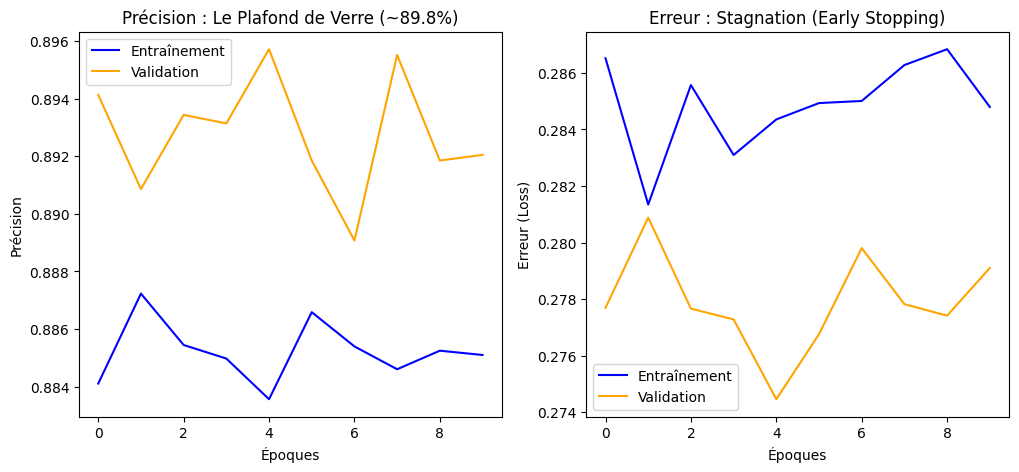

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# 1. Courbe de la Précision
plt.subplot(1, 2, 1)
plt.plot(history_ultimate.history['accuracy'], label='Entraînement', color='blue')
plt.plot(history_ultimate.history['val_accuracy'], label='Validation', color='orange')
plt.title('Précision : Le Plafond de Verre (~89.8%)')
plt.xlabel('Époques')
plt.ylabel('Précision')
plt.legend()

# 2. Courbe de l'Erreur (Loss)
plt.subplot(1, 2, 2)
plt.plot(history_ultimate.history['loss'], label='Entraînement', color='blue')
plt.plot(history_ultimate.history['val_loss'], label='Validation', color='orange')
plt.title('Erreur : Stagnation (Early Stopping)')
plt.xlabel('Époques')
plt.ylabel('Erreur (Loss)')
plt.legend()

plt.show()

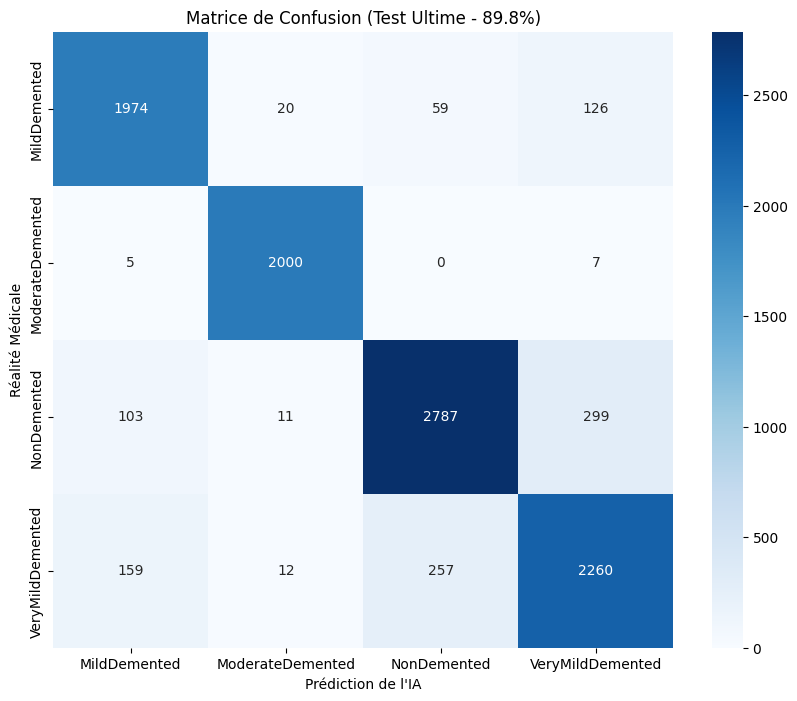

In [16]:
import matplotlib.pyplot as plt

# 1. On complète la ligne qui était coupée pour récupérer les noms des maladies
class_labels = list(val_generator.class_indices.keys())

# 2. On affiche directement la Matrice de Confusion
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_labels, yticklabels=class_labels)
plt.title('Matrice de Confusion (Test Ultime - 89.8%)')
plt.ylabel('Réalité Médicale')
plt.xlabel('Prédiction de l\'IA')
plt.show()